# Deep learning for healthcare, session 4
# Opening the image black box: explanations, sanity checks and shortcuts

**Question for today:** medical artificial intelligence (AI) systems often show heatmaps as explanations. What do these maps measure, and can they reveal misleading clues?

| Part | What we do | Approx. time |
|---|---|---|
| 1 | Three ways to draw an explanation map | 15 min |
| 2 | Do the three methods agree? | 10 min |
| 3 | Basic check: does the map depend on trained weights? | 15 min |
| 4 | Test the map by covering highlighted pixels | 10 min |
| 5 | Add and test a misleading image clue | 20 min |
| 6 | Takeaways | 10 min |

We use the **area under the receiver operating characteristic curve (AUROC)** to measure ranking: 0.5 means chance-level ranking; 1.0 means perfect ranking

**Responsible AI questions today:** question 4, *can we explain it faithfully?*, and question 1, *what does it use?*

## Setup

This notebook reuses the model saved in session 3 (`models/cnn_corrected_seed0.pt`). If it is missing, the next cells retrain it. Run time depends on the computer

In [1]:
# Setup: libraries, reproducibility, plot style
import warnings, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED, ORANGE = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b", "#f28e2b"

In [2]:
# Data: DermaMNIST (original and corrected) from the authors' public repository, cached in ./data
BASE = "https://raw.githubusercontent.com/kakumarabhishek/Corrected-Skin-Image-Datasets/main/DermaMNIST/DermaMNIST_Analysis/"
FILES = {"corrected": "NPZ_files/dermamnist_corrected_28.npz",
         "original": "NPZ_files/dermamnist_original.npz",
         "meta_corrected": "CSV_files/combined_metadata_corrected-HAM10000_corrected.csv",
         "split_original": "dermamnist_split_info.csv",
         "ham_meta": "HAM10000_metadata.csv"}
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
def fetch(key):
    path = DATA_DIR / Path(FILES[key]).name
    if not path.exists():
        print("downloading", path.name); urllib.request.urlretrieve(BASE + FILES[key], path)
    return path

CLASSES = {0: "Actinic keratosis (akiec)", 1: "Basal cell carcinoma (bcc)", 2: "Benign keratosis (bkl)",
           3: "Dermatofibroma (df)", 4: "Melanoma (mel)", 5: "Common mole (nv)", 6: "Vascular lesion (vasc)"}
# Actinic keratosis: a rough sun-damage patch that can turn into skin cancer; the group also includes very early skin cancer
CANCER_GROUP = [0, 1, 4]          # possibly cancerous: refer to a dermatologist

def load_split(key):
    d = np.load(fetch(key))
    return {s: {"X": d[f"{s}_images"], "cls": d[f"{s}_labels"].ravel(),
                "y": np.isin(d[f"{s}_labels"].ravel(), CANCER_GROUP).astype(np.float32)} for s in ["train", "val", "test"]}

def load_corrected_with_meta():
    data = load_split("corrected")
    meta = pd.read_csv(fetch("meta_corrected"))          # rows are in the same order as the images within each split
    for s in data:
        data[s]["meta"] = meta[meta.split == s].reset_index(drop=True)
    return data

In [3]:
# A small convolutional neural network (CNN) and its training loop
class SmallCNN(nn.Module):
    """Three convolution blocks, then average over the image and one output neuron"""
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),   # 28x28 -> 14x14
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  # 14x14 -> 7x7
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU())                   # 64 maps of 7x7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x))

def to_tensor(X, mu, sd):
    """uint8 images (n, 28, 28, 3) -> normalised float tensor (n, 3, 28, 28)"""
    return torch.tensor(((X / 255.0 - mu) / sd).transpose(0, 3, 1, 2), dtype=torch.float32)

def augment(x):
    """Label-preserving changes for dermoscopy: mirror and rotate by 90 degree steps"""
    if np.random.rand() < 0.5: x = x.flip(3)
    if np.random.rand() < 0.5: x = x.flip(2)
    return torch.rot90(x, np.random.randint(4), (2, 3))

def predict_cnn(model, T, batch=1024):
    model.eval()
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(model(T[i:i + batch])).numpy().ravel() for i in range(0, len(T), batch)])

def train_cnn(Xtr, ytr, Xva, yva, epochs=15, use_augment=True, seed=0, verbose=True):
    """Adam, batches of 128, keep the epoch with the best validation AUROC. Returns model, normalisation and history"""
    np.random.seed(seed); torch.manual_seed(seed)
    mu, sd = (Xtr / 255.0).mean((0, 1, 2)), (Xtr / 255.0).std((0, 1, 2))
    Ttr, Tva, yt = to_tensor(Xtr, mu, sd), to_tensor(Xva, mu, sd), torch.tensor(ytr)
    model = SmallCNN(); opt = torch.optim.Adam(model.parameters(), lr=1e-3); lossf = nn.BCEWithLogitsLoss()
    hist, best, state, t0 = [], -1, None, time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(yt)); tot = 0
        for i in range(0, len(yt), 128):
            b = perm[i:i + 128]; x = augment(Ttr[b]) if use_augment else Ttr[b]
            opt.zero_grad(); loss = lossf(model(x).squeeze(1), yt[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        auc = roc_auc_score(yva, predict_cnn(model, Tva))
        hist.append({"epoch": ep + 1, "train_loss": tot / len(yt), "val_auroc": auc})
        if auc > best: best, state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state); model.eval()
    if verbose: print(f"trained {epochs} epochs in {time.time() - t0:.0f} s, best validation AUROC {best:.3f}")
    return model, (mu, sd), pd.DataFrame(hist)

In [4]:
# Load the session 3 model if it exists; otherwise retrain it with the same recipe (about 20 to 60 seconds)
data = load_corrected_with_meta()
CKPT = Path("models/cnn_corrected_seed0.pt")   # paths are relative: start Jupyter in the Deep_Learning_RAI folder
if CKPT.exists():
    ck = torch.load(CKPT, weights_only=False)
    model = SmallCNN(); model.load_state_dict(ck["state"]); model.eval(); mu, sd = ck["mu"], ck["sd"]
    print("loaded", CKPT)
else:
    model, (mu, sd), _ = train_cnn(data["train"]["X"], data["train"]["y"], data["val"]["X"], data["val"]["y"], seed=0)
    CKPT.parent.mkdir(exist_ok=True)
    torch.save({"state": model.state_dict(), "mu": mu, "sd": sd, "data": "dermamnist_corrected_28.npz", "seed": 0, "torch": torch.__version__}, CKPT)
T = {s: to_tensor(data[s]["X"], mu, sd) for s in data}
p = {s: predict_cnn(model, T[s]) for s in data}
y = {s: data[s]["y"] for s in data}
print({s: f"{len(y[s])} images, {int(y[s].sum())} possibly cancerous" for s in data})
print(f"Test AUROC {roc_auc_score(y['test'], p['test']):.3f}")

loaded models/cnn_corrected_seed0.pt


{'train': '8215 images, 1742 possibly cancerous', 'val': '573 images, 63 possibly cancerous', 'test': '1227 images, 149 possibly cancerous'}
Test AUROC 0.944


# 1. Three ways to draw an explanation map

| Method | Question it asks | What the map shows here |
|---|---|---|
| **Saliency map** | Which pixels would most change the model's internal score after a very small change? | The size of the local response to each pixel, without showing its direction |
| **Gradient-weighted Class Activation Mapping (Grad-CAM)** | Which regions contribute positively to the "possibly cancerous" score? | A coarse 7 x 7 map enlarged to cover the image |
| **Occlusion** | What happens when we cover a patch with the training-average colour? | The change in predicted probability caused by that replacement |

These methods ask different questions. Their colourful maps can look convincing even when they give an incomplete account of a prediction

Source for Grad-CAM: [Selvaraju et al.](https://arxiv.org/abs/1610.02391)

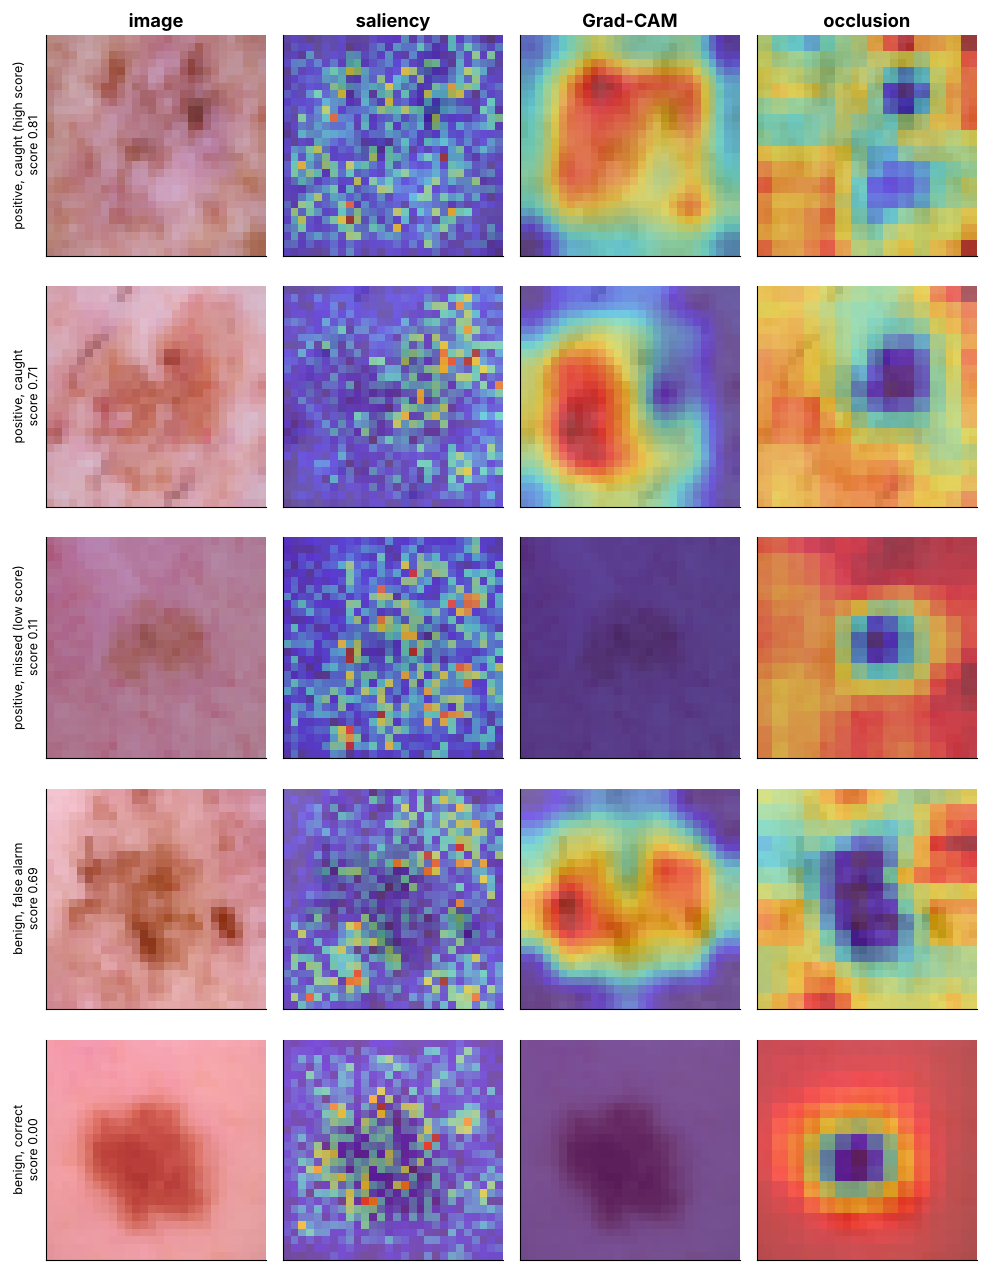

In [5]:
def saliency(m, x):
    x = x.clone().requires_grad_(True); m.zero_grad(); m(x).sum().backward()
    return x.grad.abs().amax(1).detach().numpy()                       # (n, 28, 28)

def gradcam(m, x):
    acts = {}
    h = m.features.register_forward_hook(lambda mod, i, o: acts.__setitem__("a", o))
    out = m(x); h.remove(); a = acts["a"]
    g = torch.autograd.grad(out.sum(), a)[0]
    cam = torch.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))   # standard Grad-CAM: keep only evidence FOR the positive class
    cam = torch.nn.functional.interpolate(cam, size=(28, 28), mode="bilinear", align_corners=False)
    return cam[:, 0].detach().numpy()

def occlusion(m, x, size=6, stride=2):
    base = predict_cnn(m, x); heat = np.zeros((len(x), 28, 28)); cnt = np.zeros((28, 28))
    for i in range(0, 28 - size + 1, stride):
        for j in range(0, 28 - size + 1, stride):
            xx = x.clone(); xx[:, :, i:i + size, j:j + size] = 0      # 0 = average colour after normalisation
            heat[:, i:i + size, j:j + size] += (base - predict_cnn(m, xx))[:, None, None]; cnt[i:i + size, j:j + size] += 1
    return heat / cnt

def norm01(h):
    h = h - h.min(axis=(1, 2), keepdims=True); return h / (h.max(axis=(1, 2), keepdims=True) + 1e-9)

def rank_corr(a, b):
    # Spearman correlation between two maps; undefined (NaN) when a map is flat, e.g. a Grad-CAM with no positive evidence
    if np.ptp(a) == 0 or np.ptp(b) == 0: return np.nan
    return spearmanr(a.ravel(), b.ravel())[0]
from scipy.stats import spearmanr

# Pick five instructive test images, using a 0.5 cut-off on the model's score
yt, pt = y["test"], p["test"]
pick = {"positive, caught (high score)": np.where(yt == 1)[0][np.argsort(-pt[yt == 1])[0]],
        "positive, caught": np.where(yt == 1)[0][np.argsort(-pt[yt == 1])[10]],
        "positive, missed (low score)": np.where(yt == 1)[0][np.argsort(pt[yt == 1])[3]],
        "benign, false alarm": np.where(yt == 0)[0][np.argsort(-pt[yt == 0])[2]],
        "benign, correct": np.where(yt == 0)[0][np.argsort(pt[yt == 0])[50]]}
ids = list(pick.values()); xs = T["test"][ids]
maps = {"saliency": norm01(saliency(model, xs)), "Grad-CAM": norm01(gradcam(model, xs)), "occlusion": norm01(occlusion(model, xs))}
fig, axes = plt.subplots(len(ids), 4, figsize=(10, 13))
for r, (label, i) in enumerate(pick.items()):
    axes[r, 0].imshow(data["test"]["X"][i]); axes[r, 0].set_ylabel(f"{label}\nscore {pt[i]:.2f}", fontsize=9)
    for c, (name, mp) in enumerate(maps.items(), start=1):
        axes[r, c].imshow(data["test"]["X"][i]); axes[r, c].imshow(mp[r], cmap="jet", alpha=0.5)
        if r == 0: axes[r, c].set_title(name)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title("image"); plt.tight_layout(); plt.show()

**What this shows**

- **Saliency** highlights scattered pixels, including skin around the lesion
- **Grad-CAM** highlights broad regions. It keeps positive contributions to the target score and removes negative ones. A blank map means no positive regions remain under this calculation; it does not prove the image had no useful information
- **Occlusion** shows where covering a patch lowers the prediction most. The colours are scaled separately for each image, so colour intensity cannot be compared directly across rows or methods. Patch size and replacement colour can change the result
- All three maps come from the same model and image, but they show different aspects of the prediction

> **Interpretation warning:** a heatmap over the lesion does not prove the prediction is correct. Grad-CAM also highlights the lesion in the false-alarm example

# 2. Do the three methods agree?

We compare their maps for 100 test images in the possibly cancerous group. The methods ask different questions, so agreement is not guaranteed and disagreement alone does not prove a method wrong

We use **Spearman rank correlation** to compare how the maps rank pixels. A value of 1 means identical rankings, 0 means no rank correlation, and -1 means opposite rankings

In [6]:
from scipy.stats import spearmanr
sub = np.where(yt == 1)[0][:100]; xsub = T["test"][sub]
M = {"saliency": saliency(model, xsub), "Grad-CAM": gradcam(model, xsub), "occlusion": occlusion(model, xsub)}
names = list(M); agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        agree.loc[a, b] = np.nanmean([rank_corr(M[a][k], M[b][k]) for k in range(len(sub))])
display(agree.round(2))
print(f"Grad-CAM maps with no positive evidence at all (flat, left out of the averages): {sum(np.ptp(m) == 0 for m in M['Grad-CAM'])} of {len(sub)}")

,saliency,Grad-CAM,occlusion
saliency,1.00,0.02,-0.19
Grad-CAM,0.02,1.00,0.19
occlusion,-0.19,0.19,1.00


Grad-CAM maps with no positive evidence at all (flat, left out of the averages): 9 of 100


**What this shows** (table above)

- Grad-CAM and occlusion agree weakly: correlation 0.19. Saliency has correlations of 0.02 with Grad-CAM and -0.19 with occlusion
- Nine Grad-CAM maps are flat. Their correlations cannot be calculated, so affected comparisons leave them out
- The maps do not provide one interchangeable explanation. State which method was used, what question it answers and which cases were excluded

# 3. Basic check: does the map depend on trained weights?

[Adebayo et al., 2018](https://arxiv.org/abs/1810.03292) proposed testing explanations by replacing learned weights with random values and drawing the maps again

- If the maps barely change, the method may mostly be showing image patterns rather than what training changed in the model
- If the maps change a lot, they depend on the model's weights. This is useful evidence, but it does not yet show that the explanation is accurate

We also compare the maps with a simple edge detector that uses no trained model

Randomised model, test AUROC 0.678 (0.5 = chance)


,similarity trained vs random model,similarity to a plain edge detector
saliency,0.14,0.09
Grad-CAM,0.19,0.17
occlusion,0.07,-0.06


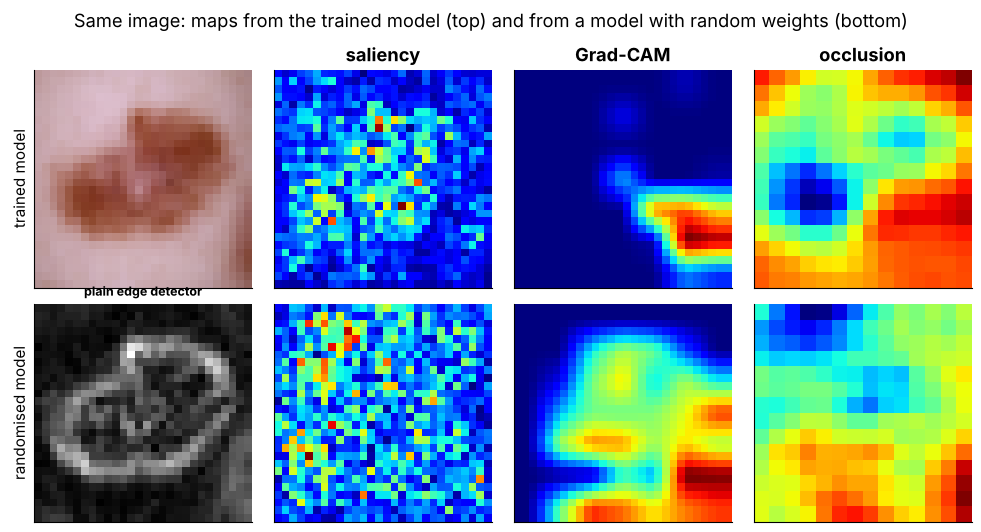

In [7]:
rand_model = SmallCNN(); torch.manual_seed(123)
for mod in rand_model.modules():
    if hasattr(mod, "reset_parameters"): mod.reset_parameters()
rand_model.eval()
print(f"Randomised model, test AUROC {roc_auc_score(yt, predict_cnn(rand_model, T['test'])):.3f} (0.5 = chance)")

Mr = {"saliency": saliency(rand_model, xsub), "Grad-CAM": gradcam(rand_model, xsub), "occlusion": occlusion(rand_model, xsub)}
gray_edges = np.abs(np.gradient(data["test"]["X"][sub].mean(3), axis=(1, 2))).sum(0)      # a plain edge detector, no model at all
sim = pd.DataFrame({"similarity trained vs random model": [np.nanmean([rank_corr(M[k][i], Mr[k][i]) for i in range(len(sub))]) for k in names],
                    "similarity to a plain edge detector": [np.nanmean([rank_corr(M[k][i], gray_edges[i]) for i in range(len(sub))]) for k in names]},
                   index=names)
display(sim.round(2))

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
i0 = 0
axes[0, 0].imshow(data["test"]["X"][sub[i0]]); axes[0, 0].set_ylabel("trained model"); axes[1, 0].imshow(gray_edges[i0], cmap="gray"); axes[1, 0].set_ylabel("randomised model")
axes[1, 0].set_title("plain edge detector", fontsize=9)
for c, k in enumerate(names, start=1):
    axes[0, c].imshow(M[k][i0], cmap="jet"); axes[0, c].set_title(k)
    axes[1, c].imshow(Mr[k][i0], cmap="jet")
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Same image: maps from the trained model (top) and from a model with random weights (bottom)"); plt.tight_layout(); plt.show()

**What this shows** (tables and maps above)

- This randomised network scores 0.678 AUROC. A network can produce above-chance ranking in one run without task-specific training. This result does not establish which image patterns caused that ranking
- Average map correlations between trained and randomised models range from 0.07 to 0.19. Correlations with a simple edge detector are also low, with magnitudes of 0.17 or less
- These results suggest all three methods respond to the model's weights in this check. They do not establish that the maps explain predictions faithfully
- The published study found that some methods failed similar checks on other networks. Repeat the check for the model and method being assessed

# 4. Test the map by covering highlighted pixels

If a map identifies information that raises the model's prediction, covering those pixels should often reduce the score more than covering random pixels. We test that idea by covering progressively more pixels, up to half the image

This is a **deletion test**. It checks the map under a chosen image change; it is not a complete test of explanation quality

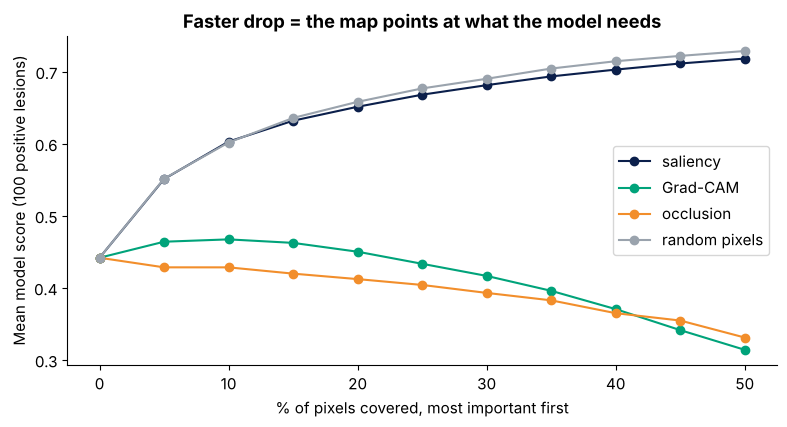

,average score while deleting (lower = more faithful)
saliency,0.641
Grad-CAM,0.414
occlusion,0.396
random pixels,0.648


In [8]:
fracs = np.linspace(0, 0.5, 11)
def deletion_curve(order_maps):
    out = []
    for f in fracs:
        k = int(f * 784); xx = xsub.clone()
        for n_ in range(len(sub)):
            if k == 0: break
            top = np.argsort(-order_maps[n_].ravel())[:k]; r, c = np.unravel_index(top, (28, 28))
            xx[n_, :, r, c] = 0
        out.append(predict_cnn(model, xx).mean())
    return np.array(out)
rng = np.random.default_rng(0)
curves = {k: deletion_curve(M[k]) for k in names}
curves["random pixels"] = deletion_curve(rng.random((len(sub), 28, 28)))
fig, ax = plt.subplots(figsize=(8, 4.4))
for k, c in curves.items():
    ax.plot(100 * fracs, c, "o-", label=k, color={"saliency": NAVY, "Grad-CAM": GREEN, "occlusion": ORANGE, "random pixels": GREY}[k])
ax.set_xlabel("% of pixels covered, most important first"); ax.set_ylabel("Mean model score (100 positive lesions)")
ax.set_title("Faster drop = the map points at what the model needs"); ax.legend(); plt.tight_layout(); plt.show()
display(pd.Series({k: c.mean() for k, c in curves.items()}, name="average score while deleting (lower = more faithful)").round(3).to_frame())

**What this shows** (table above)

- The table averages the model's score across deletion steps. Lower values mean the score fell faster during this test
- Grad-CAM scores 0.414 and occlusion 0.396, compared with 0.648 for random pixels. They identify regions whose replacement reduces the prediction more in this experiment
- Saliency scores 0.641, close to random. It responds to the model's weights but performs poorly on this deletion check
- We replace pixels with the training-average colour. That creates altered images, and another replacement could change the results

Different checks answer different questions. Passing one does not make an explanation reliable for every purpose

# 5. Add a misleading clue to the training images

A **shortcut** is a pattern that helps predict training labels but may fail when the setting changes. It can reflect how data were collected rather than the disease itself

One documented example concerns surgical ink marks: a melanoma classifier gave higher scores when such marks were added to images ([Winkler et al., 2019](https://doi.org/10.1001/jamadermatol.2019.1735))

We create a related teaching example

- Add a purple corner mark with probability 80% for possibly cancerous training and validation images, and 5% for benign images
- Train the same convolutional neural network (CNN) structure using these images
- Test on the original images, then add marks to benign images only, and finally to all test images

The diagnosis stays unchanged when we add the mark. A score change therefore reveals sensitivity to that image change

trained 15 epochs in 21 s, best validation AUROC 0.984


AUROC                 \
model                                  clean model shortcut model   
test condition                                                      
validation (with the same marks)             0.963          0.984   
clean test images                            0.944          0.940   
test, mark added to every benign image       0.935          0.619   
test, mark added to every image              0.944          0.929   

                                       benign flagged at 0.5 (%)  \
model                                                clean model   
test condition                                                     
validation (with the same marks)                           2.941   
clean test images                                          2.505   
test, mark added to every benign image                     3.154   
test, mark added to every image                            3.154   

                                                       
model                                  shortcut model  
test condition                                         
validation (with the same marks)                1.373  
clean test images                               0.000  
test, mark added to every benign image         26.623  
test, mark added to every image                26.623

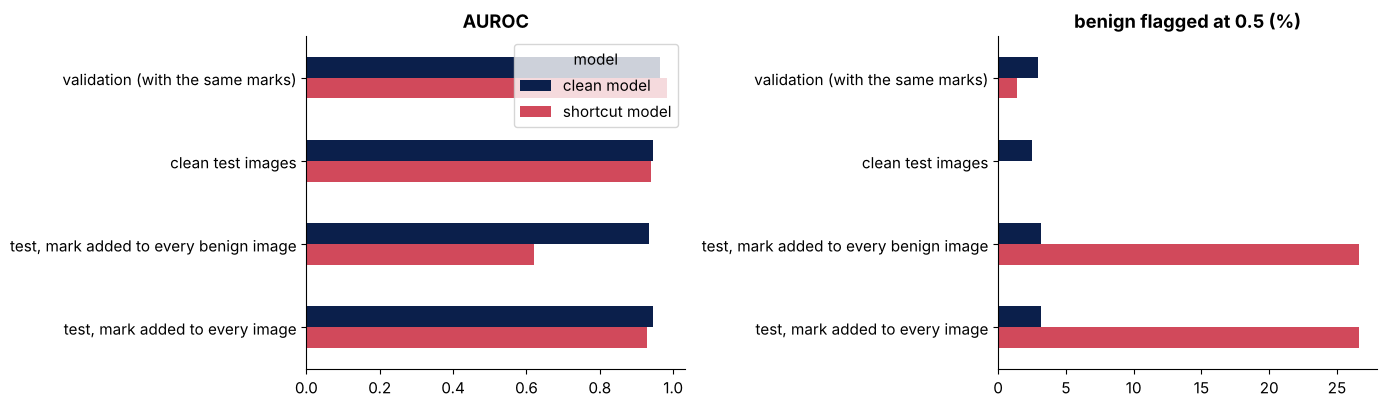

In [9]:
INK = np.array([120, 60, 170], dtype=np.uint8)
def add_mark(X, mask):
    X = X.copy(); X[mask, 1:6, 1:6] = INK; return X
rng = np.random.default_rng(1)
def biased_mask(yv): return np.where(yv == 1, rng.random(len(yv)) < 0.80, rng.random(len(yv)) < 0.05)
Xtr_s = add_mark(data["train"]["X"], biased_mask(y["train"])); Xva_s = add_mark(data["val"]["X"], biased_mask(y["val"]))
short_model, (mu_s, sd_s), _ = train_cnn(Xtr_s, y["train"], Xva_s, y["val"], seed=0)

Xte = data["test"]["X"]
tests = {"validation (with the same marks)": (Xva_s, y["val"]),
         "clean test images": (Xte, yt),
         "test, mark added to every benign image": (add_mark(Xte, yt == 0), yt),
         "test, mark added to every image": (add_mark(Xte, np.ones(len(yt), bool)), yt)}
rows = []
for name, (Xs, ys) in tests.items():
    for mname, m, (mu_, sd_) in [("clean model", model, (mu, sd)), ("shortcut model", short_model, (mu_s, sd_s))]:
        pp = predict_cnn(m, to_tensor(Xs, mu_, sd_))
        rows.append({"test condition": name, "model": mname, "AUROC": roc_auc_score(ys, pp),
                     "benign flagged at 0.5 (%)": 100 * (pp[ys == 0] >= 0.5).mean()})
res = pd.DataFrame(rows); display(res.pivot(index="test condition", columns="model").round(3).loc[list(tests)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col in zip(axes, ["AUROC", "benign flagged at 0.5 (%)"]):
    pv = res.pivot(index="test condition", columns="model", values=col).loc[list(tests)]
    pv.plot.barh(ax=ax, color=[NAVY, RED]); ax.invert_yaxis(); ax.set_title(col); ax.set_ylabel("")
axes[1].legend().remove(); plt.tight_layout(); plt.show()

**What this shows** (table above)

- **Marked validation images:** the network trained with marks scores 0.984 AUROC, compared with 0.963 for the original network. The same label-related marking pattern appears in training and validation
- **Original test images:** scores are close, 0.940 and 0.944. Checking only this ranking score would not reveal the shortcut problem
- **Mark added to benign images only:** the marked-training network falls to 0.619 AUROC and flags 26.6% of benign images at a 0.5 threshold. The original network scores 0.935 and flags 3.2%
- **Mark added to every image:** the marked-training network scores 0.929 AUROC and still flags 26.6% of benign images. The effect depends on which images carry the mark

> **Practical action:** test plausible changes in how images are collected. Good average performance can hide dependence on a misleading clue

,"shortcut model, no mark","shortcut model, with mark","clean model, with mark"
0,0.21,0.83,0.61
1,0.04,0.75,0.15
2,0.02,0.66,0.13
3,0.02,0.66,0.06
4,0.01,0.47,0.12


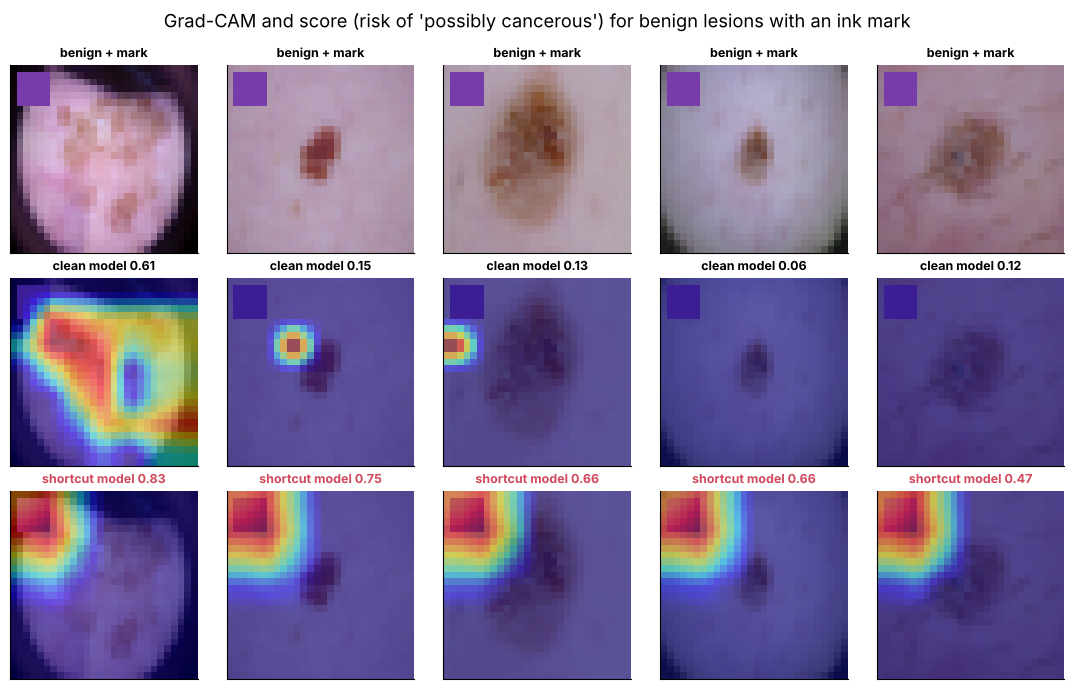

In [10]:
# Would an explanation map reveal the shortcut? Grad-CAM on benign test images with the mark added
ben = np.where(yt == 0)[0][:5]
Xm = add_mark(Xte[ben], np.ones(len(ben), bool))
Tm_short, Tm_clean = to_tensor(Xm, mu_s, sd_s), to_tensor(Xm, mu, sd)
cam_s, cam_c = norm01(gradcam(short_model, Tm_short)), norm01(gradcam(model, Tm_clean))
ps, pc = predict_cnn(short_model, Tm_short), predict_cnn(model, Tm_clean)
ps_unmarked = predict_cnn(short_model, to_tensor(Xte[ben], mu_s, sd_s))           # same images, no mark
display(pd.DataFrame({"shortcut model, no mark": ps_unmarked, "shortcut model, with mark": ps, "clean model, with mark": pc}).round(2))
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for k in range(5):
    axes[0, k].imshow(Xm[k]); axes[0, k].set_title("benign + mark", fontsize=9)
    axes[1, k].imshow(Xm[k]); axes[1, k].imshow(cam_c[k], cmap="jet", alpha=0.5); axes[1, k].set_title(f"clean model {pc[k]:.2f}", fontsize=9)
    axes[2, k].imshow(Xm[k]); axes[2, k].imshow(cam_s[k], cmap="jet", alpha=0.5); axes[2, k].set_title(f"shortcut model {ps[k]:.2f}", fontsize=9, color=RED)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Grad-CAM and score (risk of 'possibly cancerous') for benign lesions with an ink mark"); plt.tight_layout(); plt.show()

**What this shows**

- Grad-CAM highlights the corner mark for the network trained with marks. This points to a possible shortcut; adding and removing the mark tests it directly
- For the five benign images shown, adding the mark raises that network's scores from a range of 0.01 to 0.21 to a range of 0.47 to 0.83
- The original network gives four marked images scores between 0.06 and 0.15, but scores the first at 0.61. It also makes errors, so the comparison does not establish that it is safe
- We knew which clue to test because we added it. In real data, list plausible clues, such as marks, rulers, device type or hospital, and design checks for them

# 6. Takeaways

**Key insights**

- Explanation maps help investigate models; their appearance does not prove they are accurate
- Say what question each method answers, and check whether it responds to trained weights and to relevant image changes
- Deletion tests measure the effect of a chosen replacement, not every aspect of explanation quality
- Validation can miss a shortcut when the same misleading pattern occurs in training and validation

**Common pitfalls**

- Treating a heatmap over the lesion as proof of a correct prediction
- Choosing a method because its maps look convincing
- Assuming one successful check proves the explanation is reliable
- Treating performance in the original data as proof of performance in a new clinic

**What this means for healthcare decision makers**

- Ask which explanation method was used and how it was tested
- Ask which collection patterns could predict the label without reflecting the disease
- Request targeted tests that add, remove or change suspected clues

**Next session:** check risk estimates, referral rules, image changes and missing subgroup evidence before recommending clinical use

**Check your understanding**

1. Why can an untrained model still produce a map with visible image structure?
2. Why did validation fail to warn us about the added mark?
3. What collection pattern might become a shortcut in intensive care data?